# 1. Setting up things, importing files and implementing corrections

Importing the necessary packages

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statistics

from matplotlib.pyplot import rc_context

In [2]:
sc.settings.verbosity = 3             # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.logging.print_header()
sc.settings.set_figure_params(dpi=80, facecolor='white') #dpi=300

/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scanpy==1.9.5 anndata==0.8.0 umap==0.5.4 numpy==1.26.4 scipy==1.10.1 pandas==1.5.3 scikit-learn==1.2.1 statsmodels==0.13.5 igraph==0.10.4 louvain==0.8.0 pynndescent==0.5.8


Importing the mtx files for Control, 2.5% and 5% AG02 and 3% La. These file were created by the cell calling script. 

In [3]:
Ctr_adata = sc.read_10x_mtx('2023_02_23-Cp_Ctrl_BHI')
AG02_25_adata = sc.read_10x_mtx('2023_02_23-Cp_2.5p_Bl-04/rerun_h5_to_cell_calling_auguast_2023')
AG02_5_adata = sc.read_10x_mtx('2023_02_23-Cp_5p_Bl-04')
AG01_adata = sc.read_10x_mtx('2023_03_23_Cp_NCFM')

--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


UMI correction: Defining the correction factor and applying it to the individual datasets

In [4]:
umi_ctr = 12.41
umi_25 = 10.87
umi_5 = 4.15
umi_AG01 = 11.09

Ctr_adata.X = Ctr_adata.X/umi_ctr
AG02_25_adata.X = AG02_25_adata.X/umi_25
AG02_5_adata.X = AG02_5_adata.X/umi_5
AG01_adata.X = AG01_adata.X/umi_AG01

Checking the files

In [5]:
Ctr_adata

AnnData object with n_obs × n_vars = 1460 × 3189
    var: 'gene_ids', 'feature_types'

In [6]:
AG02_25_adata

AnnData object with n_obs × n_vars = 2873 × 3189
    var: 'gene_ids', 'feature_types'

In [7]:
AG02_5_adata

AnnData object with n_obs × n_vars = 5043 × 3189
    var: 'gene_ids', 'feature_types'

In [8]:
AG01_adata

AnnData object with n_obs × n_vars = 1871 × 3189
    var: 'gene_ids', 'feature_types'

Reducing the size to 1460 for all samples with a seed for reproducibility

In [9]:
#Subsampling using a random seed - NOTE: the control does not get subsampled! Every other sample gets subsampled 
#to the size of the control sample. it is included here to keep the file names consistent for all samples

seed = 0 #seed makes is reproducible between runs

Ctr_adata_sub = Ctr_adata
AG02_5_adata_sub = sc.pp.subsample(AG02_5_adata, n_obs=1460, copy=True, random_state=seed)
AG02_25_adata_sub = sc.pp.subsample(AG02_25_adata, n_obs=1460, copy=True, random_state=seed)
AG01_adata_sub = sc.pp.subsample(AG01_adata, n_obs=1460, copy=True, random_state=seed)

Checking the files

In [10]:
Ctr_adata_sub.obs["n_genes"] = (Ctr_adata_sub.X > 0).sum(axis=1).A1
Ctr_adata_sub.obs["n_genes"].describe()

count    1460.000000
mean      280.415068
std       257.306359
min        83.000000
25%       113.000000
50%       172.000000
75%       362.500000
max      2359.000000
Name: n_genes, dtype: float64

In [11]:
AG02_25_adata_sub.obs["n_genes"] = (AG02_25_adata_sub.X > 0).sum(axis=1).A1
AG02_25_adata_sub.obs["n_genes"].describe()

count    1460.000000
mean      339.573288
std       259.900286
min       139.000000
25%       199.000000
50%       232.000000
75%       385.000000
max      2836.000000
Name: n_genes, dtype: float64

In [12]:
AG02_5_adata_sub.obs["n_genes"] = (AG02_5_adata_sub.X > 0).sum(axis=1).A1
AG02_5_adata_sub.obs["n_genes"].describe()

count    1460.000000
mean      426.796575
std       295.448262
min       143.000000
25%       249.000000
50%       335.000000
75%       489.750000
max      2522.000000
Name: n_genes, dtype: float64

In [13]:
AG01_adata_sub.obs["n_genes"] = (AG01_adata_sub.X > 0).sum(axis=1).A1
AG01_adata_sub.obs["n_genes"].describe()

count    1460.000000
mean      384.963014
std       304.853614
min       125.000000
25%       217.000000
50%       268.000000
75%       431.750000
max      3036.000000
Name: n_genes, dtype: float64

# 2. Combining different datasets to make the adata file and remove rRNA genes

Combining the datasets

In [14]:
# Combining the subsamples datasets

adata = Ctr_adata.concatenate((AG02_25_adata_sub, AG02_5_adata_sub, AG01_adata_sub), batch_categories=['Control', '2.5% Ba', '5% Ba', '3% La'])


/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],
/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  [AnnData(sparse.csr_matrix(a.shape), obs=a.obs) for a in all_adatas],
/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/anndata/_core/anndata.py:1785: FutureWarning: X.dtype being

In [15]:
adata

AnnData object with n_obs × n_vars = 5840 × 3189
    obs: 'n_genes', 'batch'
    var: 'gene_ids', 'feature_types'

Removing the 5 rRNA genes for which we still have probes. They were annotated as rRNA genes in different annotations of the ONT based sequence. Some of these genes are super highly expressed - remove them to get expression of CDSs.

In [16]:
adata = adata[:, ~adata.var_names.isin(["AD4700001_03210", "AD4700001_03211", "AD4700001_01962","AD4700001_03138", "AD4700001_03207"])]

In [17]:
adata

View of AnnData object with n_obs × n_vars = 5840 × 3184
    obs: 'n_genes', 'batch'
    var: 'gene_ids', 'feature_types'

# 3. Preprocessing the data - remove cells with few genes, remove genes with low counts and normalize

normalizing counts per cell
    finished (0:00:00)


/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)
/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:169: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  view_to_actual(adata)


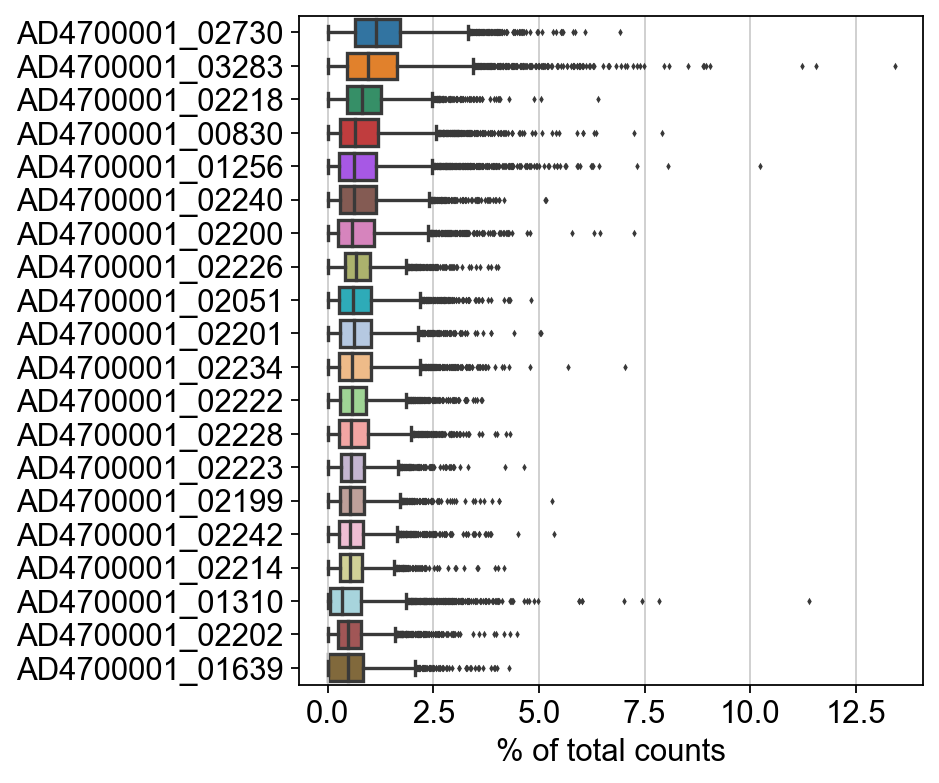

In [18]:
sc.pl.highest_expr_genes(adata, n_top=20)

Filter out genes that occure in few cells and cell with few genes

In [19]:
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=3)

filtered out 138 cells that have less than 100 genes expressed
filtered out 68 genes that are detected in less than 3 cells


In [20]:
adata.obs["batch"].value_counts()

2.5% Ba    1460
5% Ba      1460
3% La      1460
Control    1322
Name: batch, dtype: int64

Calculating QC metrics and add the information to the adata file

In [21]:
sc.pp.calculate_qc_metrics(adata, percent_top=None, log1p=False, inplace=True)

In [22]:
adata

AnnData object with n_obs × n_vars = 5702 × 3116
    obs: 'n_genes', 'batch', 'n_genes_by_counts', 'total_counts'
    var: 'gene_ids', 'feature_types', 'n_cells', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

In [23]:
adata.obs.groupby("batch")["total_counts"].agg(n_cells="count", mean_UMIs="mean",median_UMIs="median", max_UMIs="max")

,n_cells,mean_UMIs,median_UMIs,max_UMIs
batch,,,,
Control,1322,67.273170,31.023369,1900.322266
2.5% Ba,1460,82.645844,36.614532,7217.571289
5% Ba,1460,341.949646,156.144577,19366.503906
3% La,1460,139.235275,47.339943,23652.298828


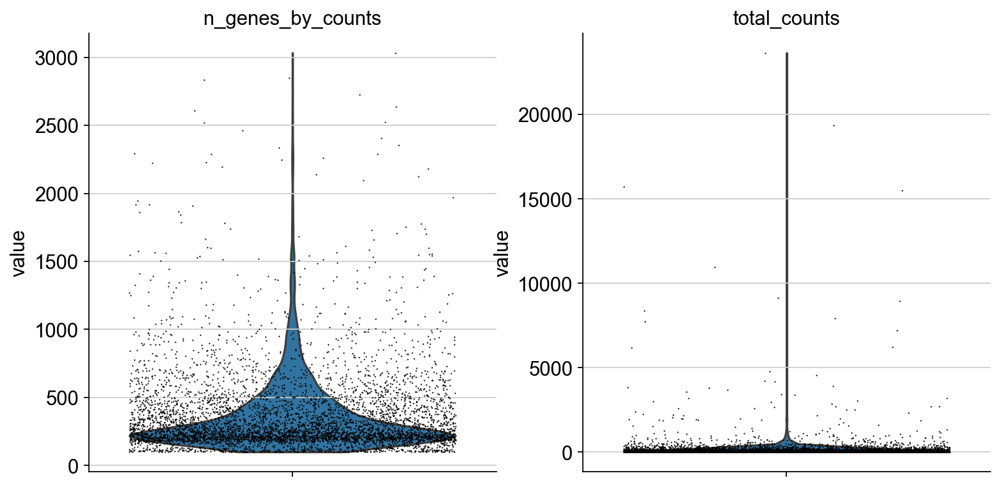

In [24]:
fig = sc.pl.violin(adata, ['n_genes_by_counts','total_counts'],jitter=0.4, multi_panel=True)

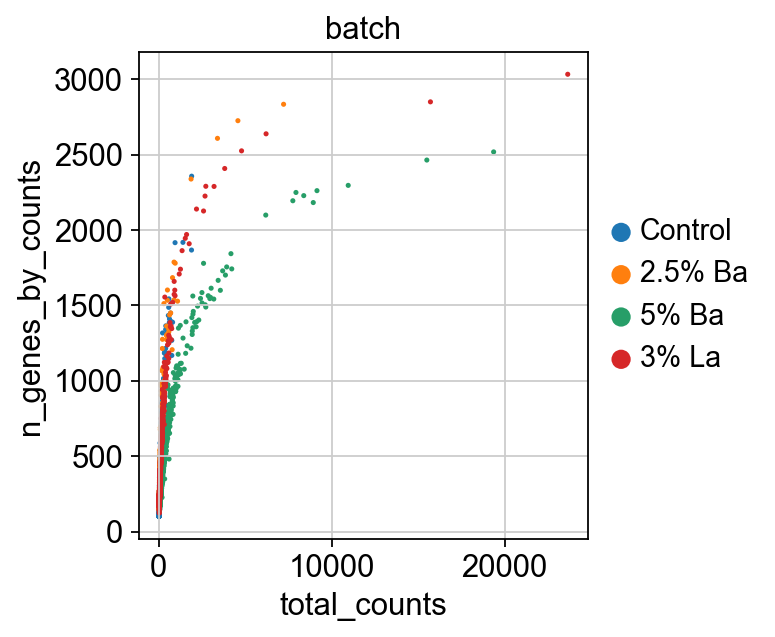

In [25]:
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='batch')

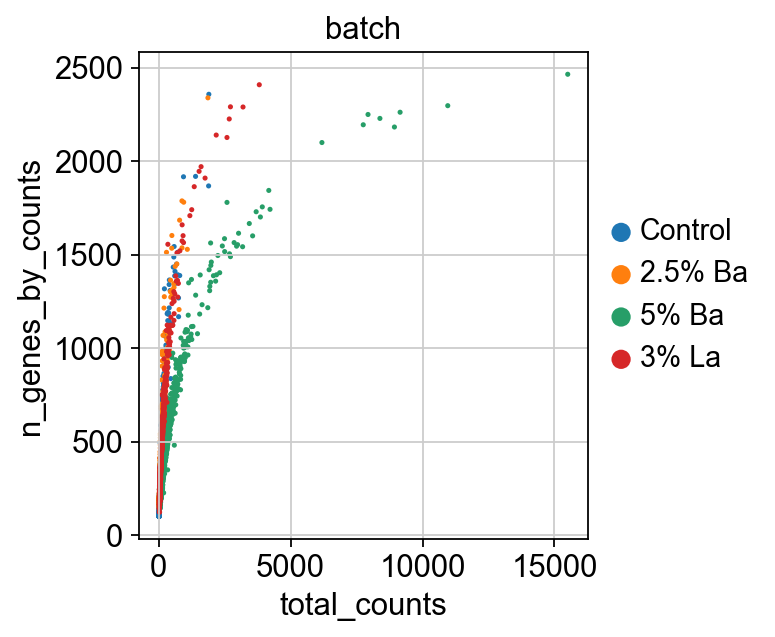

In [26]:
adata = adata[adata.obs.n_genes_by_counts <2500, :]
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color= 'batch')

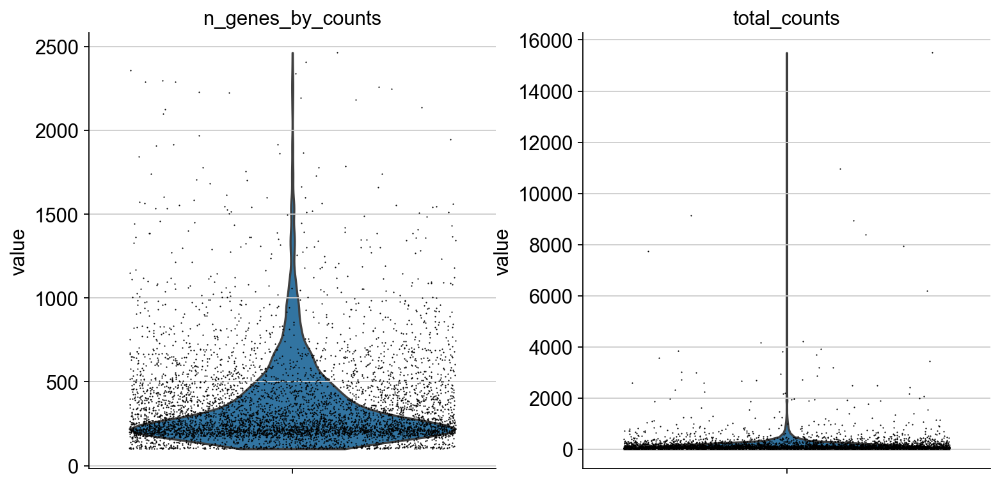

In [27]:
fig = sc.pl.violin(adata, ['n_genes_by_counts','total_counts'],jitter=0.4, multi_panel=True)

In [28]:
adata.obs.groupby("batch")["total_counts"].agg(n_cells="count", mean_UMIs="mean",median_UMIs="median", max_UMIs="max")

,n_cells,mean_UMIs,median_UMIs,max_UMIs
batch,,,,
Control,1322,67.273170,31.023369,1900.322266
2.5% Ba,1457,72.392899,36.522545,1865.869263
5% Ba,1459,328.910217,156.144577,15501.927734
3% La,1456,105.033676,47.249775,3812.173096


Normalizing the data with no target sum normalizes on the median before normalization

In [29]:
sc.pp.normalize_total(adata) 

normalizing counts per cell
    finished (0:00:00)


/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [30]:
sc.pp.log1p(adata)

In [31]:
adata

AnnData object with n_obs × n_vars = 5694 × 3116
    obs: 'n_genes', 'batch', 'n_genes_by_counts', 'total_counts'
    var: 'gene_ids', 'feature_types', 'n_cells', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'batch_colors', 'log1p'

In [32]:
adata.obs.groupby("batch")["total_counts"].agg(n_cells="count", mean_UMIs="mean", median_UMIs="median", max_UMIs="max")

,n_cells,mean_UMIs,median_UMIs,max_UMIs
batch,,,,
Control,1322,67.273170,31.023369,1900.322266
2.5% Ba,1457,72.392899,36.522545,1865.869263
5% Ba,1459,328.910217,156.144577,15501.927734
3% La,1456,105.033676,47.249775,3812.173096


Highly variable genes

In [34]:
sc.pp.highly_variable_genes(adata, min_mean=0.0125, max_mean=3, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


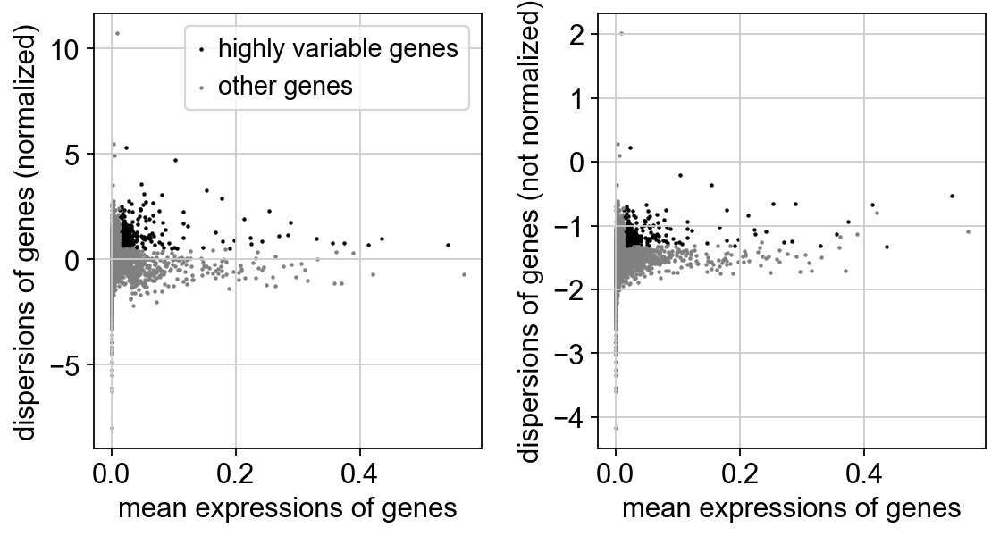

In [35]:
sc.pl.highly_variable_genes(adata)

In [36]:
adata.raw = adata

In [37]:
adata

AnnData object with n_obs × n_vars = 5694 × 3116
    obs: 'n_genes', 'batch', 'n_genes_by_counts', 'total_counts'
    var: 'gene_ids', 'feature_types', 'n_cells', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'batch_colors', 'log1p', 'hvg'

In [38]:
adata.obs["mean_expr_per_cell"] = np.asarray(adata.X.mean(axis=1)).flatten()
adata.obs["median_expr_per_cell"] = np.median(adata.X.toarray(), axis=1)

adata.obs.groupby("batch").agg(n_cells=("batch", "size"),
                                mean_cell_expression=("mean_expr_per_cell", "mean"),
                                median_cell_expression=("median_expr_per_cell", "median"))

,n_cells,mean_cell_expression,median_cell_expression
batch,,,
Control,1322,0.015986,0.0
2.5% Ba,1457,0.016623,0.0
5% Ba,1459,0.016779,0.0
3% La,1456,0.016640,0.0


In [39]:
adata.obs.groupby("batch")["n_genes_by_counts"].agg(mean="mean", median="median")

,mean,median
batch,,
Control,297.661120,191.0
2.5% Ba,332.721345,229.0
5% Ba,423.604524,333.0
3% La,376.456044,265.0


In [40]:
adata.obs.groupby("batch")["total_counts"].agg(mean="mean",median="median")

,mean,median
batch,,
Control,67.273170,31.023369
2.5% Ba,72.392899,36.522545
5% Ba,328.910217,156.144577
3% La,105.033676,47.249775


# 4. Calcultating PCA and UMAP

In [41]:
sc.tl.pca(adata, svd_solver='arpack')

computing PCA
    on highly variable genes
    with n_comps=50
    finished (0:00:00)


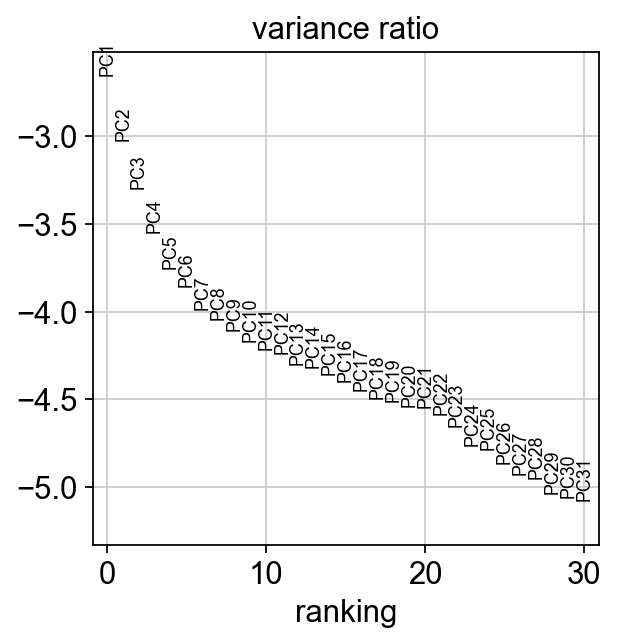

In [44]:
sc.pl.pca_variance_ratio(adata, log=True)

In [46]:
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40, random_state=seed)

computing neighbors
    using 'X_pca' with n_pcs = 40
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)


In [47]:
sc.tl.umap(adata, random_state=seed)

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:04)


/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


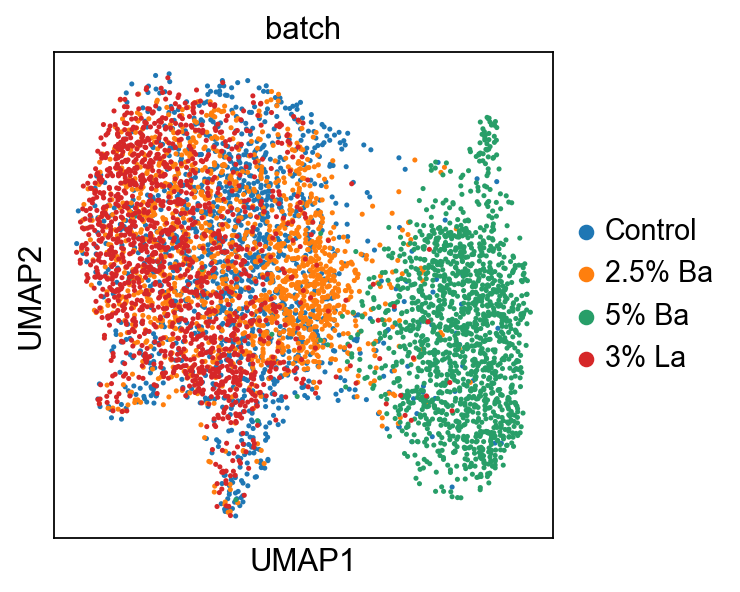

In [50]:
sc.set_figure_params(dpi=80)
sc.pl.umap(adata, color='batch')

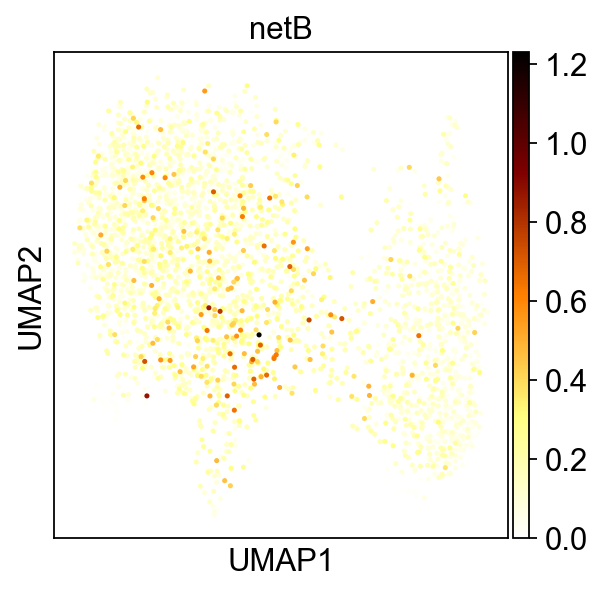

In [51]:
sc.pl.umap(adata, color=['AD4700001_02732'], color_map="afmhot_r", title="netB")

In [52]:
sc.tl.louvain(adata, resolution = 0.95, random_state=seed)

running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 8 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


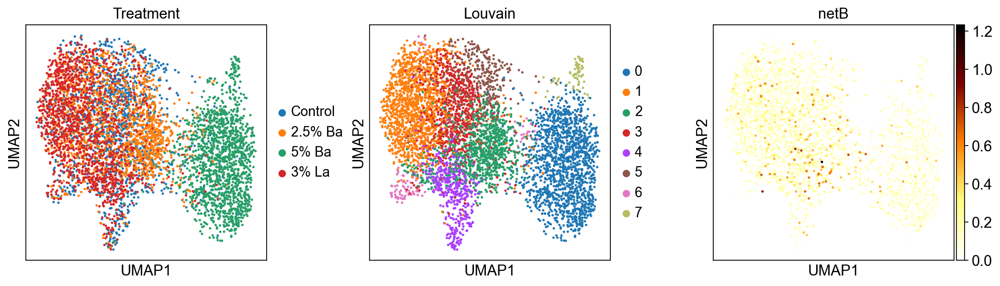

In [53]:
sc.set_figure_params(dpi=80)
sc.pl.umap(adata, color=['batch', 'louvain', 'AD4700001_02732'],color_map= "afmhot_r", legend_loc="right margin", wspace= 0.3, 
           title=["Treatment", "Louvain", "netB"])

# 5. Statistical Test for netB expression

In [57]:
#exporting all the normalized expresssion data
adata_df = adata.to_df()
adata_df["batch"] = adata.obs["batch"]
adata_df["louvain"] = adata.obs["louvain"]
adata_df["total_counts"] = adata.obs["total_counts"]
adata_df.to_csv("Expression_all_genes.csv")

In [54]:
#exporting netB expression data separately
netB = adata[:, ["AD4700001_02732"]].to_df()
netB["batch"] = adata.obs["batch"].values
netB["louvain"] = adata.obs["louvain"].values
netB

,AD4700001_02732,batch,louvain
AAACGAAAGGTCGTAG-1-Control,0.272718,Control,5
AAACGAAGTGACAGGT-1-Control,0.000000,Control,5
AAACGCTAGATTGGGC-1-Control,0.237656,Control,4
AAACGCTCAAGACCTT-1-Control,0.127206,Control,5
AAACGCTTCAACGAGG-1-Control,0.153582,Control,2
...,...,...,...
GAAGCGACAATTAGGA-1-3% La,0.159717,3% La,3
TCATTACGTATCAGCT-1-3% La,0.000000,3% La,1
TGCAGATGTCCTACAA-1-3% La,0.000000,3% La,1
TGGAACTCAGGTTACT-1-3% La,0.113210,3% La,1


netB expression by batch

In [55]:
netB.groupby("batch").agg(
    pct_expressing=("AD4700001_02732", lambda x: (x > 0).mean()*100),
    mean_expr=("AD4700001_02732", "mean"),
    median_expr=("AD4700001_02732", "median"),
    max_expr = ("AD4700001_02732", "max")
)

,pct_expressing,mean_expr,median_expr,max_expr
batch,,,,
Control,50.151286,0.093370,0.009868,1.231979
2.5% Ba,45.916266,0.075913,0.000000,0.688410
5% Ba,53.941056,0.058316,0.035310,0.648814
3% La,59.958791,0.082030,0.058844,0.522356


In [56]:
netB.to_csv("NetB_expression.csv", index=False) 

In [57]:
netB_control = netB.loc[(netB['batch']=='Control'), "AD4700001_02732" ]
netB_25 = netB.loc[(netB['batch']=='2.5% Ba'), "AD4700001_02732" ]
netB_5 = netB.loc[(netB['batch']=='5% Ba'), "AD4700001_02732" ]
netB_La = netB.loc[(netB['batch']=='3% La'), "AD4700001_02732" ]

In [58]:
print("mean Control: ", statistics.mean(netB_control.tolist()),"\n",
      "2.5 % Bl: ", statistics.mean(netB_25.tolist()),scipy.stats.ttest_ind(netB_control.tolist(), netB_25.tolist(), equal_var=False), "\n",
      "5% Bi: ", statistics.mean(netB_5.tolist()), scipy.stats.ttest_ind(netB_control.tolist(), netB_5.tolist(), equal_var=False),"\n",
      "3% La", statistics.mean(netB_La.tolist()), scipy.stats.ttest_ind(netB_control.tolist(), netB_La.tolist(), equal_var=False))

mean Control:  0.09336971947232912 
 2.5 % Bl:  0.07591294782528975 Ttest_indResult(statistic=3.5634663289952857, pvalue=0.00037292161982155515) 
 5% Bi:  0.05831596917792583 Ttest_indResult(statistic=7.937619446933953, pvalue=3.4485364581832006e-15) 
 3% La 0.08203003999833428 Ttest_indResult(statistic=2.42513691600932, pvalue=0.015380582201808834)


Calculating differential expression and making the file for GSEA

NetB statistics

In [61]:
from statannotations.Annotator import Annotator

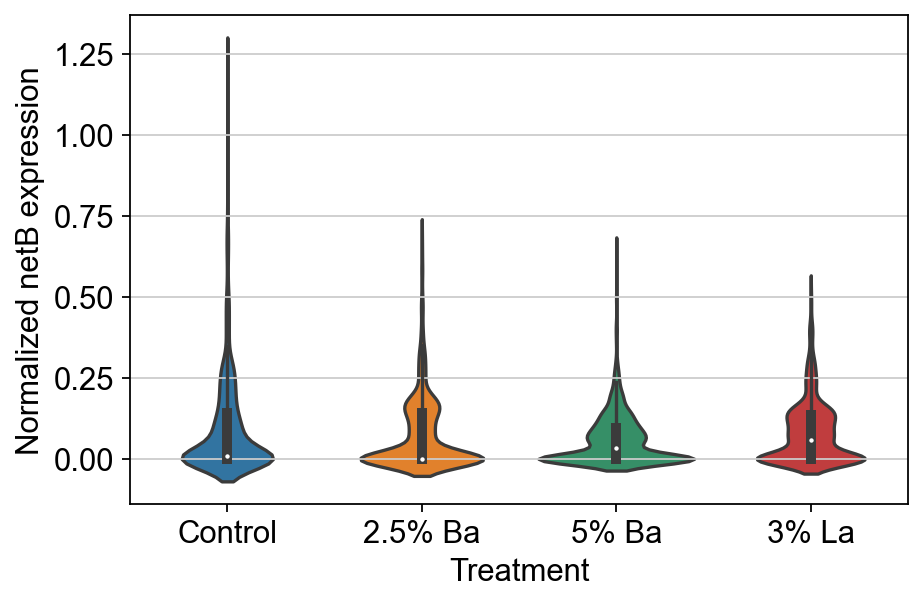

In [63]:
sc.set_figure_params(dpi=80)
# this is only to make sure we are using the right data. the final graph using the Dunn test results from above are done in R


#ax = sns.boxplot(data=netB, x="batch", y= "AD4700001_02732",)


with rc_context({'figure.figsize': (6, 4)}):
    ax = sns.violinplot(data=netB, x="batch", y="AD4700001_02732")
    ax.set_xlabel("Treatment")
    ax.set_ylabel("Normalized netB expression")
    
#pairs = [(i[1]["index"], i[1]["variable"]) for i in netB_df_short.iterrows()]
#p_values = [i[1]["value"] for i in netB_df_short.iterrows()]

#annotator = Annotator(ax, pairs, data=netB, x="batch", y="AD4700001_02732")
#annotator.configure(text_format="star", loc="inside")
#annotator.set_pvalues_and_annotate(p_values)

plt.tight_layout()


Statistical summary

In [64]:
adata.obs['batch'].value_counts()

5% Ba      1459
2.5% Ba    1457
3% La      1456
Control    1322
Name: batch, dtype: int64

In [65]:
adata.obs['louvain'].value_counts()

0    1458
1    1386
2    1004
3     848
4     479
5     332
6     119
7      68
Name: louvain, dtype: int64

In [66]:
print('Genes by count: mean = ', adata.obs["n_genes_by_counts"].mean(), ', median = ',adata.obs["n_genes_by_counts"].median())

Genes by count: mean =  359.0519845451352 , median =  263.0


In [67]:
print('Total counts: mean = ', adata.obs["total_counts"].mean(), ', median: ', adata.obs["total_counts"].median())

Total counts: mean =  145.27936 , median:  60.09321


In [68]:
print('Number of cells: mean = ', adata.var['n_cells'].mean(), 'median = ', adata.var['n_cells'].median())

Number of cells: mean =  663.0850449293966 median =  339.5


In [69]:
print('Mean count: mean = ', adata.var['mean_counts'].mean(), 'median = ', adata.var['mean_counts'].median())

Mean count: mean =  0.05133708 median =  0.012417186


In [70]:
np.max(adata.X)

3.0031483

# 6. Files for GSEA analyses

In [60]:
# Cluster markers
sc.tl.rank_genes_groups(
    adata,
    groupby='louvain',
    method='wilcoxon',
    corr_method='benjamini-hochberg',
    key_added='rank_genes_groups_louvain')

# Tidy output
markers = sc.get.rank_genes_groups_df(adata,group=None,key='rank_genes_groups_louvain')

markers.to_csv("ALL_1vsAll_Clusters_Differential.csv", index=False)

# GSEA output
result = adata.uns['rank_genes_groups_louvain']
groups = result['names'].dtype.names

gsea_df = pd.DataFrame({
    group + '_' + key[:1]: result[key][group]
    for group in groups
    for key in ['names','logfoldchanges','pvals','pvals_adj']})

gsea_df.to_csv("ALL_1vsAll_Clusters_For_GSEA.csv")

ranking genes
    finished: added to `.uns['rank_genes_groups_louvain']`
    'names', sorted np.recarray to be indexed by group ids
    'scores', sorted np.recarray to be indexed by group ids
    'logfoldchanges', sorted np.recarray to be indexed by group ids
    'pvals', sorted np.recarray to be indexed by group ids
    'pvals_adj', sorted np.recarray to be indexed by group ids (0:00:00)


# 7. Virulence factors

Defining the virulence factors

In [72]:
vir_geier = ['AD4700001_02732', 'AD4700001_02106', 'AD4700001_02810', 
             'AD4700001_01453', 'AD4700001_03244', 'AD4700001_00553', 
             'AD4700001_02074', 'AD4700001_02842', 'AD4700001_03253', 
             'AD4700001_00079', 'AD4700001_00456', 'AD4700001_02941', 
             'AD4700001_03225']

In [73]:
virulence_gene_dict_named = {
    'Toxin': {'netB': 'AD4700001_02732', 'plc':  'AD4700001_02106', 'ccp':  'AD4700001_02810', 'cpb2': 'AD4700001_01453'},
    'Collagenase': {'colA': 'AD4700001_03244'},
    'Hyaluronidase': {'nagH': 'AD4700001_03225','nagI': 'AD4700001_02842','nagJ': 'AD4700001_00553','nagK': 'AD4700001_02074'},
    'Perfringolysin': {'pfoA': 'AD4700001_03253'},
    'Sialidase': {'nanI': 'AD4700001_00079','nanJ': 'AD4700001_00456','nanH': 'AD4700001_02941'}}

In [74]:
virulence_gene_dict = {'Toxin': ['AD4700001_02732','AD4700001_02106', 'AD4700001_02810', 'AD4700001_01453'],
                      'Collagenase':'AD4700001_03244',
                      'Hyaluronidase': ['AD4700001_03225', 'AD4700001_02842','AD4700001_00553','AD4700001_02074' ], 
                       'Perfringolysin': 'AD4700001_03253', 
                       'Sialidase':['AD4700001_00079','AD4700001_00456','AD4700001_02941']}

Dotplot of virulence factors by batch

/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


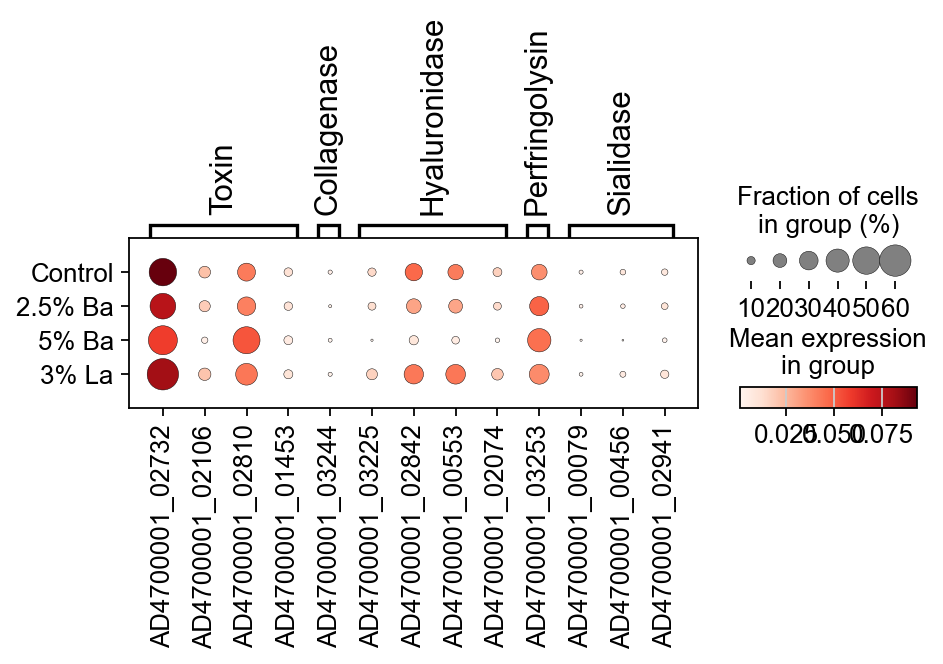

In [75]:
sc.pl.dotplot(adata, virulence_gene_dict,groupby='batch')

Dotpolot of virulence factors by cluster

/opt/homebrew/Caskroom/miniforge/base/envs/scanpy/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:748: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


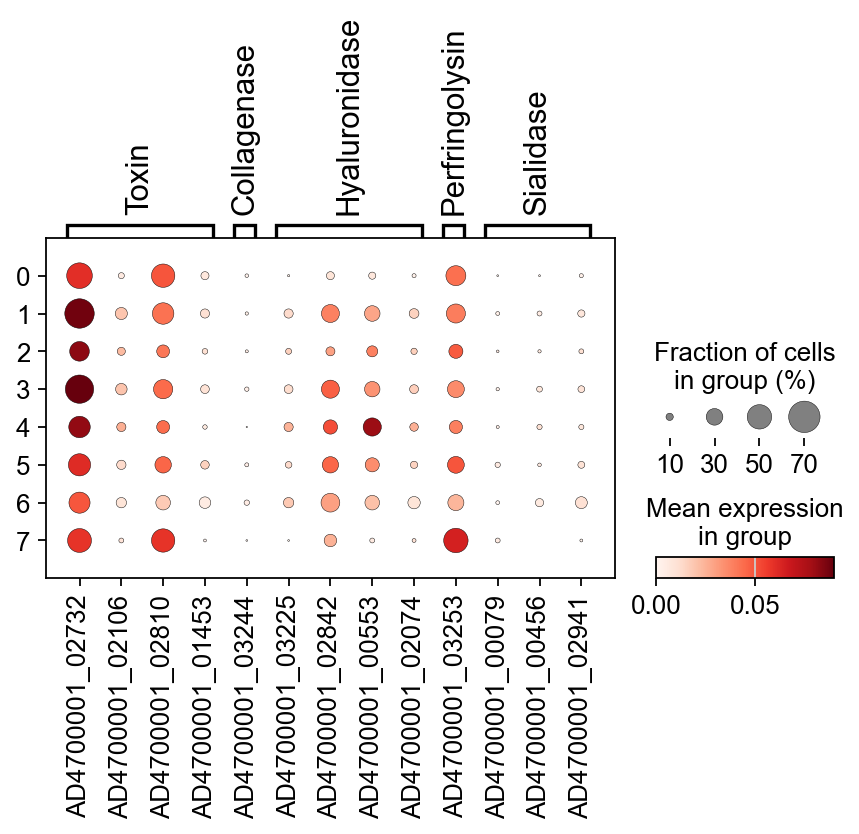

In [76]:
sc.pl.dotplot(adata, virulence_gene_dict, groupby='louvain')

# 8. Differential expression 

Differential expression files (log2FC) - Control versus ONE treatment for all genes

This takes the log transformed data, transformes it back to not log transformed, then calculates the mean expression per gene per batch and then calculates the log2fold change using log to the base of 2. 
The log fold 2 change calculated by scanpy using the rank_gene_group command give an estimated log fold 2 change, as it usese the log transformed data. log transformations do not affect all values linearly and therefore the effect is not the same for every value. Calculating the log2 fold change as it is done here prevents the results being affected the the non-linearity of the log transformation. 

In [77]:
expr_raw = np.expm1(adata.X)

In [78]:
expr_df = pd.DataFrame(np.expm1(adata.X.toarray()), columns=adata.var_names, index=adata.obs_names)
expr_df["batch"] = adata.obs["batch"].values
batch_means = expr_df.groupby("batch").mean()

In [114]:
log2fc_25 = np.log2( (batch_means.loc["2.5% Ba"] + 1e-9) / (batch_means.loc["Control"] + 1e-9))
log2fc_5 = np.log2((batch_means.loc["5% Ba"] + 1e-9) / (batch_means.loc["Control"] + 1e-9))
log2fc_La = np.log2((batch_means.loc["3% La"] + 1e-9) / (batch_means.loc["Control"] + 1e-9))

# 9. Plotting enriched genes based on GSEA for supplemental figure

/var/folders/kv/brdsh0dj7zxckqd3mm3wnts00000gq/T/ipykernel_4518/1658347026.py:41: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axes.tight_layout()


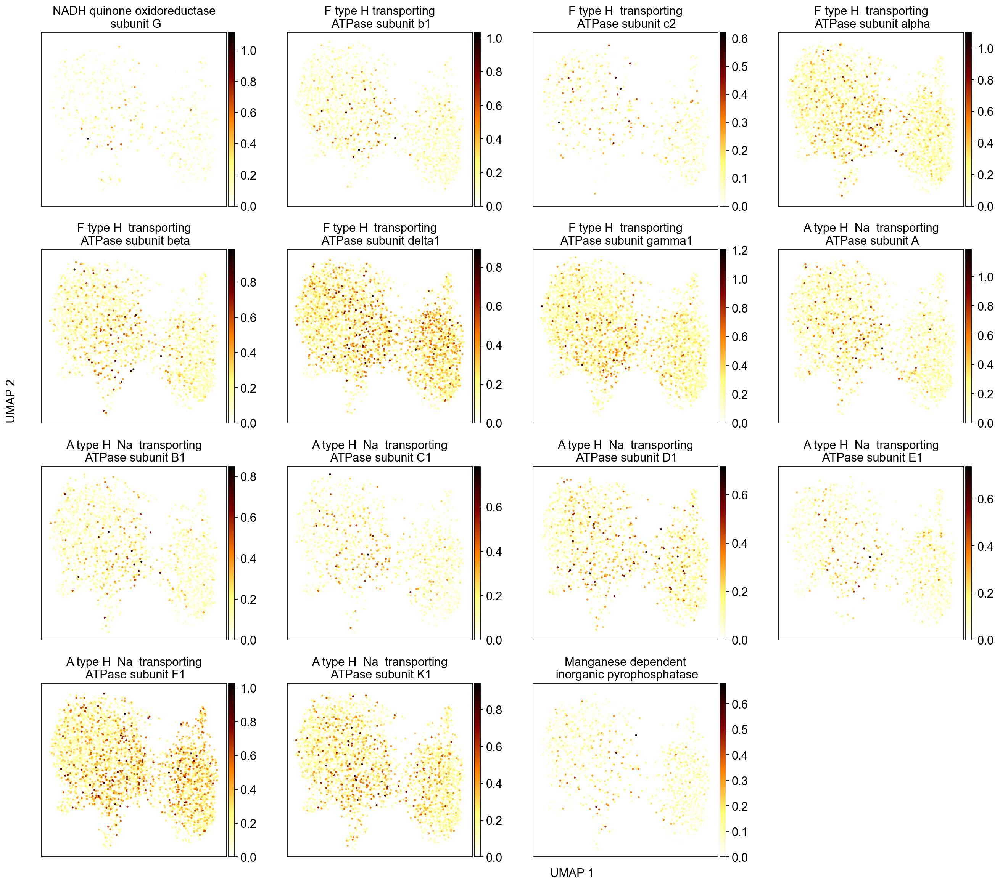

In [81]:
#00190 Oxidative phosphorylation [PATH:ko00190]

axes = sc.pl.umap(
    adata,
    color=['AD4700001_03021', 'AD4700001_01815', 'AD4700001_01816', 'AD4700001_01813', 'AD4700001_01811', 'AD4700001_01814','AD4700001_01812', 
            'AD4700001_02436', 'AD4700001_02437',  'AD4700001_02434', 'AD4700001_02438','AD4700001_02433','AD4700001_02435',  'AD4700001_02432', 
            'AD4700001_01671'],
    color_map="afmhot_r",
    ncols=4,
    title=['NADH quinone oxidoreductase\n subunit G',
                    'F type H transporting\n ATPase subunit b1',
                    'F type H  transporting\n ATPase subunit c2',
                    'F type H  transporting\n ATPase subunit alpha',
                    'F type H  transporting\n ATPase subunit beta',
                    'F type H  transporting\n ATPase subunit delta1',
                    'F type H  transporting\n ATPase subunit gamma1',
                    'A type H  Na  transporting\n ATPase subunit A',
                    'A type H  Na  transporting\n ATPase subunit B1',
                    'A type H  Na  transporting\n ATPase subunit C1',
                    'A type H  Na  transporting\n ATPase subunit D1',
                    'A type H  Na  transporting\n ATPase subunit E1',
                    'A type H  Na  transporting\n ATPase subunit F1',
                    'A type H  Na  transporting\n ATPase subunit K1',
                    'Manganese dependent\n inorganic pyrophosphatase'],
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

# Adjust spacing if needed
axes.tight_layout()

plt.show()


/var/folders/kv/brdsh0dj7zxckqd3mm3wnts00000gq/T/ipykernel_4518/3176245208.py:39: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axes.tight_layout()


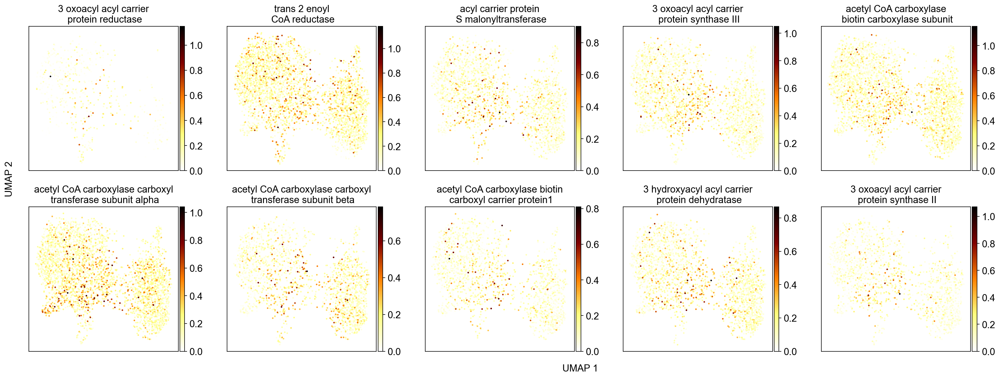

In [83]:
#00061 Fatty acid biosynthesis [PATH:ko00061]

axes = sc.pl.umap(
    adata,
    color=['AD4700001_00743', 'AD4700001_01690', 'AD4700001_00965',
        'AD4700001_00966', 'AD4700001_00960', 'AD4700001_00958',
        'AD4700001_00959', 'AD4700001_00962', 'AD4700001_00961',
        'AD4700001_00963'],
    color_map="afmhot_r",
    ncols=5,
    title=[
        '3 oxoacyl acyl carrier\n protein reductase',
        'trans 2 enoyl\n CoA reductase',
        'acyl carrier protein\n S malonyltransferase',
        '3 oxoacyl acyl carrier\n protein synthase III',
        'acetyl CoA carboxylase\n biotin carboxylase subunit',
        'acetyl CoA carboxylase carboxyl\n transferase subunit alpha',
        'acetyl CoA carboxylase carboxyl\n transferase subunit beta',
        'acetyl CoA carboxylase biotin\n carboxyl carrier protein1',
        '3 hydroxyacyl acyl carrier\n protein dehydratase',
        '3 oxoacyl acyl carrier\n protein synthase II'
    ],
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

# Adjust spacing if needed
axes.tight_layout()



plt.show()






/var/folders/kv/brdsh0dj7zxckqd3mm3wnts00000gq/T/ipykernel_4518/1990891432.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axes.tight_layout()


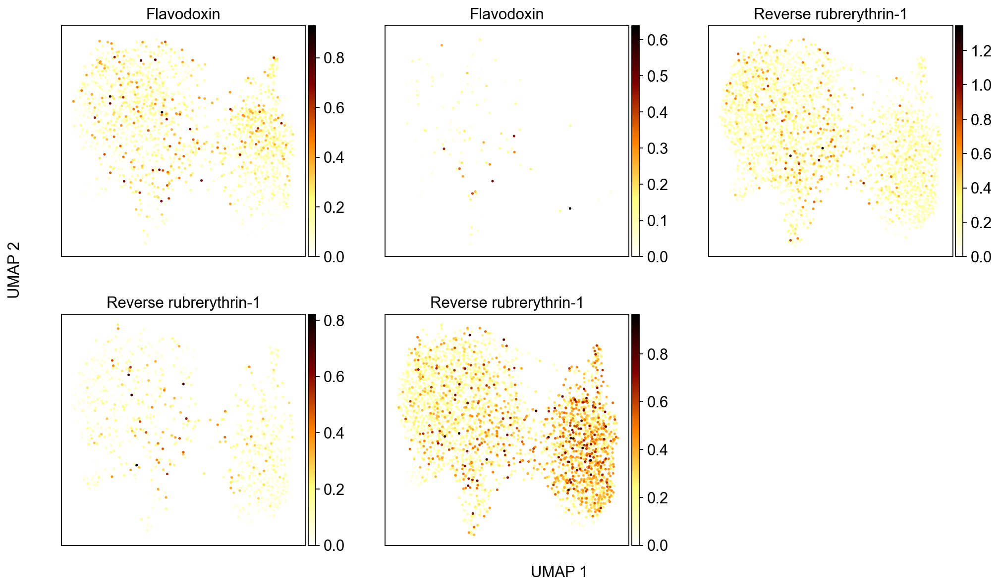

In [85]:
## 99982 Energy metabolism

axes = sc.pl.umap(
    adata,
    color=['AD4700001_00171', 'AD4700001_01786', 'AD4700001_00807', 'AD4700001_03133', 'AD4700001_00117' ],
    color_map="afmhot_r",
    ncols=3,
    title=["Flavodoxin", 
                  "Flavodoxin",
                  "Reverse rubrerythrin-1",
                  "Reverse rubrerythrin-1",
                  "Reverse rubrerythrin-1"],
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

# Adjust spacing if needed
axes.tight_layout()

plt.show()



/var/folders/kv/brdsh0dj7zxckqd3mm3wnts00000gq/T/ipykernel_4518/4246821934.py:28: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  axes.tight_layout()


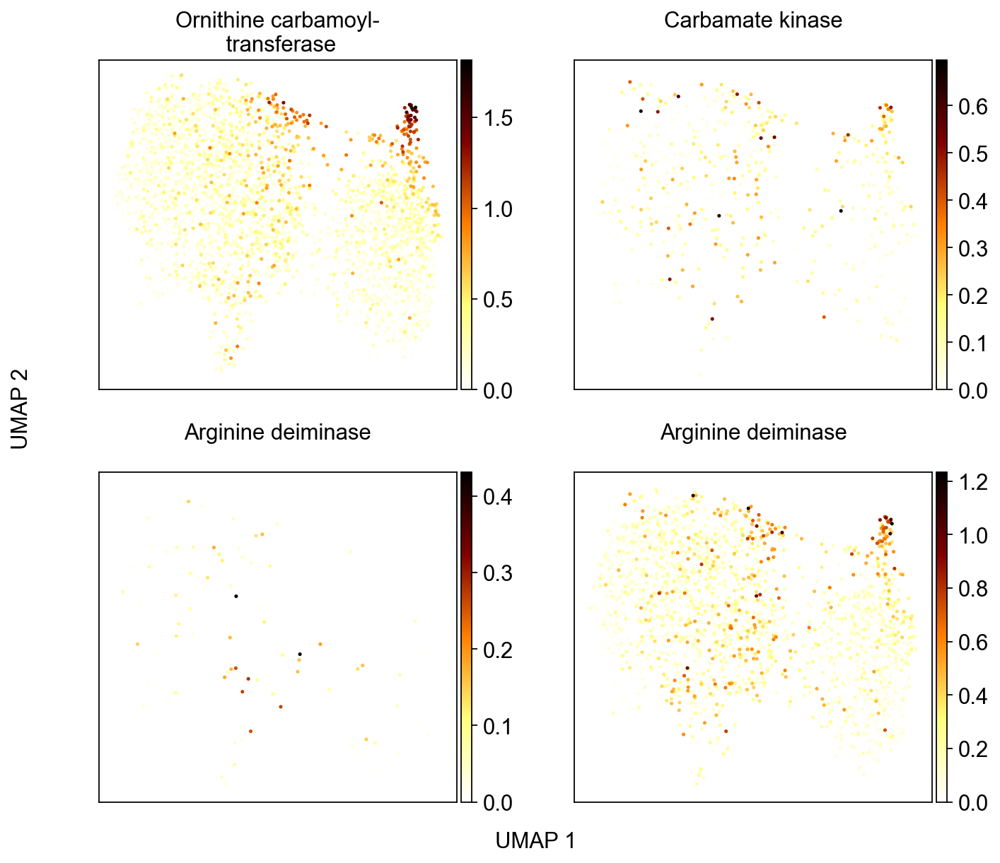

In [86]:
#02020 00220 Arginine biosynthesis [PATH:ko00220]
axes = sc.pl.umap(
    adata,
    color=['AD4700001_03248', 'AD4700001_03246', 'AD4700001_00251', 'AD4700001_03249'],
    color_map="afmhot_r",
    ncols=2,
    title=['Ornithine carbamoyl-\n transferase',
            'Carbamate kinase\n',
            'Arginine deiminase\n',
            'Arginine deiminase\n'],
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)


# Adjust spacing if needed
axes.tight_layout()



plt.show()

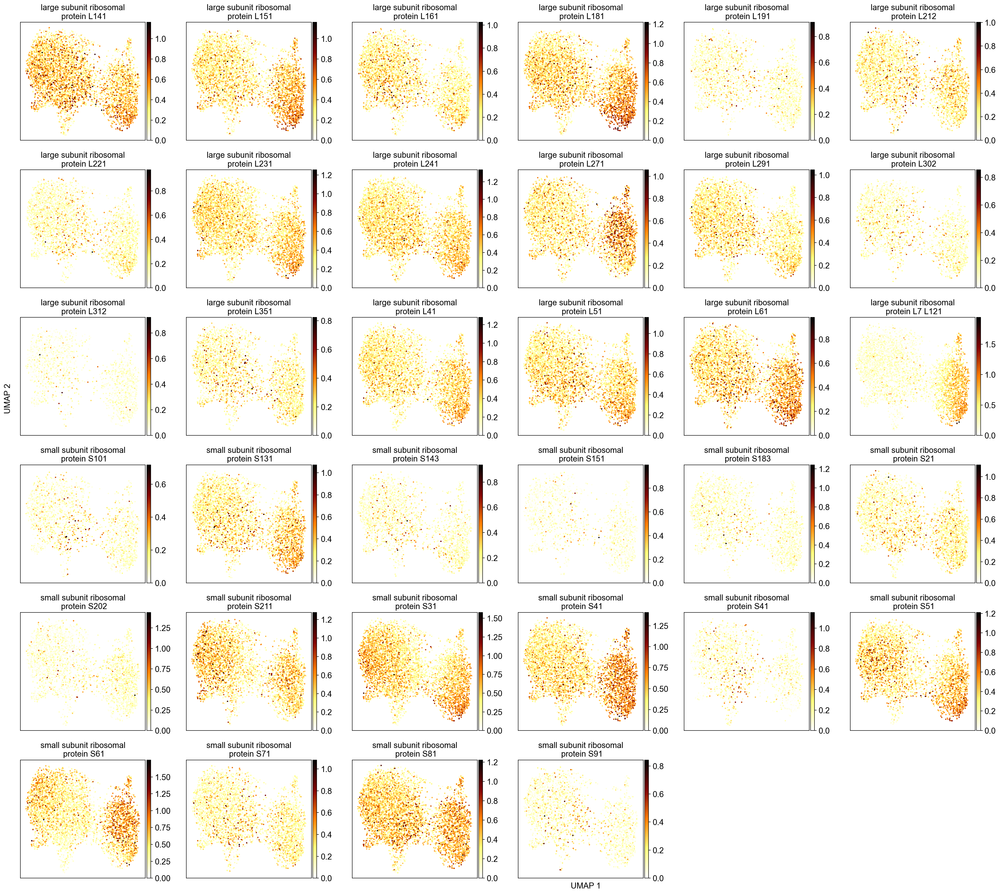

In [87]:
# Cluster 0 
# 03010 Ribosome [PATH:ko03010]





axes = sc.pl.umap(
    adata,
    color=['AD4700001_02222', 	
'AD4700001_02231', 
'AD4700001_02219', 	
'AD4700001_02228', 
'AD4700001_01240', 
'AD4700001_01745', 
'AD4700001_02217', 	
'AD4700001_02214', 
'AD4700001_02223', 
'AD4700001_01743', 
'AD4700001_02220', 
'AD4700001_02230', 
'AD4700001_01829', 
'AD4700001_01505', 
'AD4700001_02213', 
'AD4700001_02224', 	
'AD4700001_02227', 	
'AD4700001_02203', 
'AD4700001_02211', 
'AD4700001_02238', 
'AD4700001_02225', 
'AD4700001_02392', 
'AD4700001_00828', 	
'AD4700001_01232', 
'AD4700001_01658', 	
'AD4700001_01639', 	
'AD4700001_02218', 	
'AD4700001_02240', 
'AD4700001_02257', 
'AD4700001_02229', 	
'AD4700001_00830', 
'AD4700001_02208', 
'AD4700001_02226', 
'AD4700001_02248'
    ],
    color_map="afmhot_r",
    ncols=6,
    title=['large subunit ribosomal\n protein L141',
'large subunit ribosomal\n protein L151',
'large subunit ribosomal\n protein L161',
'large subunit ribosomal\n protein L181',
'large subunit ribosomal\n protein L191',
'large subunit ribosomal\n protein L212',
'large subunit ribosomal\n protein L221',
'large subunit ribosomal\n protein L231',
'large subunit ribosomal\n protein L241',
'large subunit ribosomal\n protein L271',
'large subunit ribosomal\n protein L291',
'large subunit ribosomal\n protein L302',
'large subunit ribosomal\n protein L312',
'large subunit ribosomal\n protein L351',
'large subunit ribosomal\n protein L41',
'large subunit ribosomal\n protein L51',
'large subunit ribosomal\n protein L61',
'large subunit ribosomal\n protein L7 L121',
'small subunit ribosomal\n protein S101',
'small subunit ribosomal\n protein S131',
'small subunit ribosomal\n protein S143',
'small subunit ribosomal\n protein S151',
'small subunit ribosomal\n protein S183',
'small subunit ribosomal\n protein S21',
'small subunit ribosomal\n protein S202',
'small subunit ribosomal\n protein S211',
'small subunit ribosomal\n protein S31',
'small subunit ribosomal\n protein S41',
'small subunit ribosomal\n protein S41',
'small subunit ribosomal\n protein S51',
'small subunit ribosomal\n protein S61',
'small subunit ribosomal\n protein S71',
'small subunit ribosomal\n protein S81',
'small subunit ribosomal\n protein S91'],
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

plt.show()



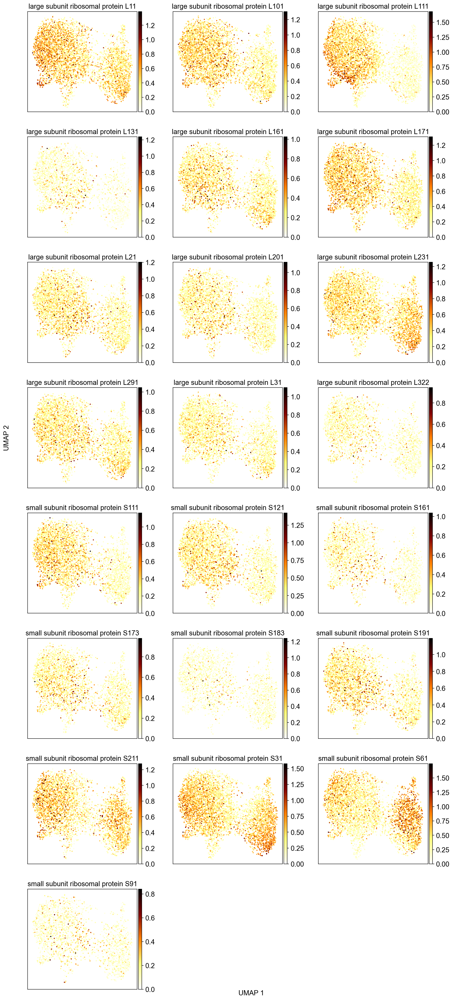

In [156]:
# Cluster 1 
# Ribosomes

axes = sc.pl.umap(
    adata,
    color=['AD4700001_02201', 'AD4700001_02202', 'AD4700001_02200', 'AD4700001_02247',  'AD4700001_02219', 'AD4700001_02242',
            'AD4700001_02215', 'AD4700001_01504', 'AD4700001_02214','AD4700001_02220', 'AD4700001_02212', 'AD4700001_01253',
            'AD4700001_02239', 'AD4700001_02207',  'AD4700001_01244', 'AD4700001_02221','AD4700001_00828',	'AD4700001_02216',	
            'AD4700001_01639','AD4700001_02218','AD4700001_00830','AD4700001_02248' ],
    
    color_map="afmhot_r",
    ncols=3,
    
    title=['large subunit ribosomal protein L11',
'large subunit ribosomal protein L101',	
'large subunit ribosomal protein L111',	
'large subunit ribosomal protein L131',	
'large subunit ribosomal protein L161',	
'large subunit ribosomal protein L171',	
'large subunit ribosomal protein L21',
'large subunit ribosomal protein L201',	
'large subunit ribosomal protein L231',
'large subunit ribosomal protein L291',	
'large subunit ribosomal protein L31',
'large subunit ribosomal protein L322',	
'small subunit ribosomal protein S111',
'small subunit ribosomal protein S121',	
'small subunit ribosomal protein S161',
'small subunit ribosomal protein S173',
'small subunit ribosomal protein S183',
'small subunit ribosomal protein S191',
'small subunit ribosomal protein S211',
'small subunit ribosomal protein S31',
'small subunit ribosomal protein S61',	
'small subunit ribosomal protein S91'],
    
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

plt.show()








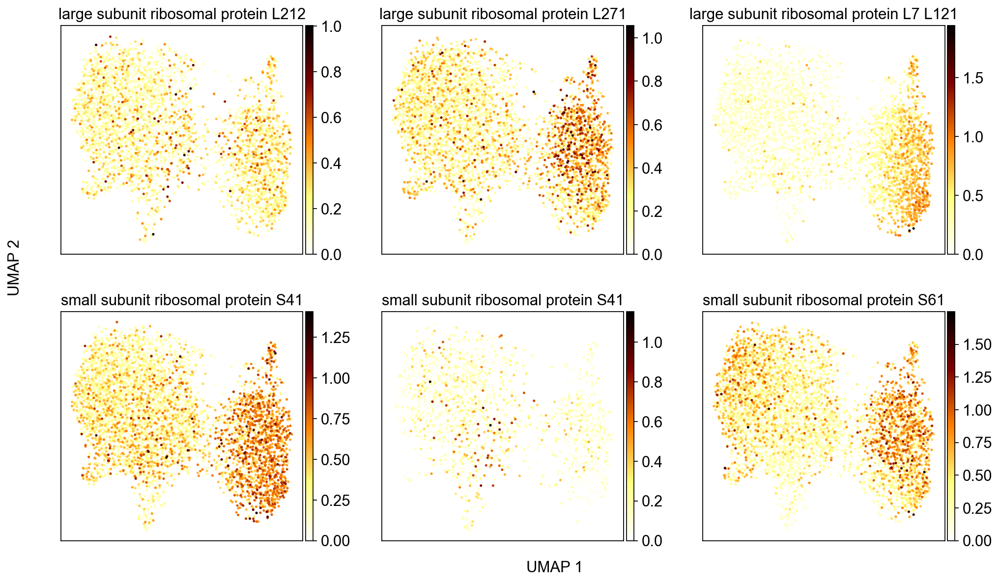

In [88]:
# Cluster 7
# Ribosomes


axes = sc.pl.umap(
    adata,
    color=['AD4700001_01745', 'AD4700001_01743', 'AD4700001_02203', 'AD4700001_02240', 'AD4700001_02257', 'AD4700001_00830'],
    
    color_map="afmhot_r",
    ncols=3,
    
    title=['large subunit ribosomal protein L212',	'large subunit ribosomal protein L271', 'large subunit ribosomal protein L7 L121',
          'small subunit ribosomal protein S41', 'small subunit ribosomal protein S41',	'small subunit ribosomal protein S61'],
    
    return_fig=True
)

# Get all UMAP panels
axs = axes.axes

# Remove individual axis labels
for ax in axs:
    ax.set_xlabel("")
    ax.set_ylabel("")

# Add global labels
axes.supxlabel("UMAP 1", fontsize=14)
axes.supylabel("UMAP 2", fontsize=14)

plt.show()



